# **07 · Evaluación final**

Este notebook evalúa una sola vez, sobre los datos de prueba, las líneas base y las cinco iteraciones entrenadas en el notebook 06. A diferencia de la validación, la prueba nunca se usó para tomar decisiones, así que es la medida honesta de cómo funcionaría el modelo con un negocio real.

Se evalúa en tres partes, una por una:

1. **Los 5 locales reservados de ddop:** el mismo tipo de panadería del entrenamiento, pero locales que el modelo nunca vio.
2. **The Bread Basket:** un negocio distinto, de otro país y con otro patrón semanal; además es el negocio de la demostración.
3. **La prueba de temporada:** julio a septiembre de French Bakery, para medir cuánto sufre el modelo cuando cambia la temporada.

## **0. Modelos y predicciones**

Se cargan los pesos de la mejor época de cada iteración, sin volver a entrenar nada. Todos los modelos se evalúan sobre los mismos días a predecir (`first_offset=28`), igual que en validación. La iteración 5 se compara con su cuantil 0.50 (la mediana); su escalera de cuantiles se usa en la parte de valor.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.baselines import same_weekday_mean, seasonal_naive
from src.metrics import evaluate
from src.models import MLP, LSTMForecaster
from src.training import DEVICE, predict
from src.windows import make_windows

MODELS, RESULTS = ROOT / "models", ROOT / "results"
df = pd.read_parquet(ROOT / "data" / "processed" / "unified.parquet")

search = pd.read_csv(RESULTS / "02_busqueda_lstm.csv").sort_values("WAPE val")
lstm_config = dict(hidden=int(search.iloc[0]["neuronas"]), layers=int(search.iloc[0]["capas"]))
QUANTILES = [0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9]

# nombre: (modelo, archivo de pesos, ventana, usa día de la semana)
models = {
    "MLP (iteración 1)": (MLP(14, 4, 3), "01_mlp.pt", 14, False),
    "LSTM base (iteración 2)": (LSTMForecaster(4, 3, **lstm_config), "02_lstm_base.pt", 14, False),
    "LSTM 28 días (iteración 3)": (LSTMForecaster(4, 3, **lstm_config), "03_lstm_28.pt", 28, False),
    "LSTM día de la semana (iteración 4)": (LSTMForecaster(6, 5, **lstm_config), "04_lstm_dia_semana.pt", 14, True),
    "LSTM cuantiles (iteración 5)": (LSTMForecaster(4, 3, quantiles=len(QUANTILES), **lstm_config), "05_lstm_cuantiles.pt", 28, False),
}
for model, weights, _, _ in models.values():
    model.load_state_dict(torch.load(MODELS / weights, map_location=DEVICE))
    model.to(DEVICE)
print("Modelos cargados:", list(models))

Modelos cargados: ['MLP (iteración 1)', 'LSTM base (iteración 2)', 'LSTM 28 días (iteración 3)', 'LSTM día de la semana (iteración 4)', 'LSTM cuantiles (iteración 5)']


In [2]:
def predictions_for(splits):
    """Predicciones (en la escala normalizada) de cada modelo sobre los mismos días."""
    reference = make_windows(df, 28, splits, first_offset=28)
    preds = {
        "Igual que la semana pasada": seasonal_naive(reference),
        "Promedio de los mismos días (28)": same_weekday_mean(reference),
    }
    full = {}
    for name, (model, _, lookback, dow) in models.items():
        w = make_windows(df, lookback, splits, use_day_of_week=dow, first_offset=28)
        assert w.meta[["product_id", "first_date"]].equals(reference.meta[["product_id", "first_date"]]), "No se compara sobre los mismos días"
        # Cada modelo normaliza con la escala de su propia ventana (14 o 28 días); se reexpresa con la
        # escala de la ventana de referencia para que todas las métricas usen las mismas unidades.
        output = predict(model, w) * (w.scale / reference.scale)[:, None, None]
        full[name] = output
        preds[name] = output[..., 0]
    return reference, preds, full


test_w, test_preds, test_full = predictions_for(["test"])
naive = test_preds["Igual que la semana pasada"]
print(f"Ejemplos de prueba: {len(test_w):,} | Por dataset: {test_w.meta['dataset'].value_counts().to_dict()}")

Ejemplos de prueba: 17,692 | Por dataset: {'ddop': 15228, 'bread_basket': 2464}


In [3]:
def results_table(windows, preds, dataset):
    """Métricas de todos los modelos para un dataset, sobre los mismos días."""
    keep = (windows.meta["dataset"] == dataset).to_numpy()
    sub = make_subset(windows, keep)
    rows = []
    for name, prediction in preds.items():
        total = evaluate(sub, prediction[keep], naive_all[keep]).loc[("Total", "")]
        rows.append(total.rename(name))
    return pd.DataFrame(rows).drop(columns="predicciones")


def make_subset(windows, keep):
    from src.windows import Windows
    return Windows(
        past=windows.past[keep], future=windows.future[keep], target=windows.target[keep],
        mask=windows.mask[keep], scale=windows.scale[keep], meta=windows.meta[keep].reset_index(drop=True),
    )


def plot_results(table, title):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    colors = ["#a9ccf2"] * 2 + ["#2f6fb5"] * (len(table) - 2)
    for ax, metric in zip(axes, ["WAPE", "MASE"]):
        ax.barh(table.index[::-1], table[metric][::-1], color=colors[::-1])
        ax.set_xlabel(metric + " (menos es mejor)")
    axes[1].axvline(1, color="gray", linestyle="--", linewidth=0.8)
    axes[1].set_yticks([])
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


naive_all = naive

## **1. Prueba en los 5 locales reservados de ddop**

Son los locales 4, 5, 17, 19 y 37, elegidos al azar con la semilla 123 antes de entrenar. Venden los mismos 3 productos que el resto de ddop, así que esta prueba responde si el modelo funciona en **locales que nunca vio** de una panadería parecida a las del entrenamiento.

Métricas:

- **MAE:** error promedio en unidades por día.
- **RMSE:** como el MAE, pero castiga más los errores grandes.
- **WAPE:** de cada 100 unidades vendidas, en cuántas se equivoca. Es la métrica principal.
- **MAE relativo:** el error total frente al de "igual que la semana pasada"; menos de 1 es mejor. Los productos que más venden pesan más.
- **MASE:** la misma comparación, pero producto por producto (por serie) y promediada; cada serie cuenta igual.

In [4]:
ddop_results = results_table(test_w, test_preds, "ddop")
ddop_results.round(3)

,MAE,RMSE,WAPE,MAE relativo,MASE
Igual que la semana pasada,25.828,47.067,0.218,1.000,1.000
Promedio de los mismos días (28),21.189,38.566,0.178,0.820,0.827
MLP (iteración 1),20.688,37.734,0.174,0.801,0.801
LSTM base (iteración 2),20.867,38.045,0.176,0.808,0.805
LSTM 28 días (iteración 3),20.245,37.359,0.170,0.784,0.781
LSTM día de la semana (iteración 4),20.385,37.390,0.172,0.789,0.789
LSTM cuantiles (iteración 5),20.418,37.692,0.172,0.791,0.787


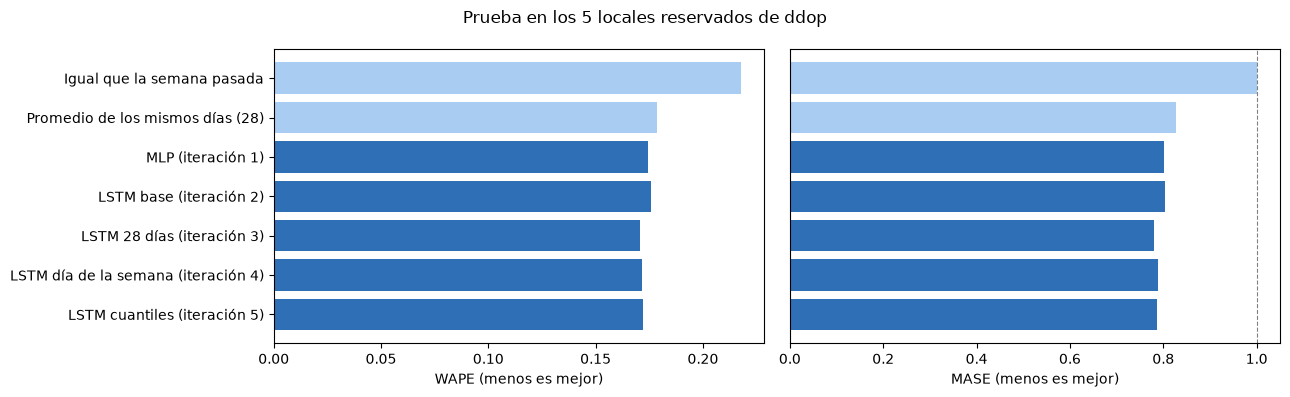

In [5]:
plot_results(ddop_results, "Prueba en los 5 locales reservados de ddop")

Como los 5 locales tienen escalas muy distintas (el local 4 vende entre 1 y 11 unidades al día y el 19 unas 200), se revisa el WAPE de cada local por separado para ver si el modelo funciona igual en uno pequeño que en uno grande.

In [6]:
keep = (test_w.meta["dataset"] == "ddop").to_numpy()
sub = make_subset(test_w, keep)
by_store = {}
for name in ["Promedio de los mismos días (28)", "LSTM base (iteración 2)", "LSTM 28 días (iteración 3)", "LSTM cuantiles (iteración 5)"]:
    table = evaluate(sub, test_preds[name][keep], naive_all[keep], by=("store_id",))
    by_store[name] = table["WAPE"].drop(index="Total")
store_scale = df[(df["dataset"] == "ddop") & df["is_open"]].groupby("store_id")["sales"].mean().rename("venta promedio diaria")
pd.DataFrame(by_store).join(store_scale).round(3)

,Promedio de los mismos días (28),LSTM base (iteración 2),LSTM 28 días (iteración 3),LSTM cuantiles (iteración 5),venta promedio diaria
store_id,,,,,
ddop_17,0.185,0.183,0.174,0.176,113.580
ddop_19,0.154,0.149,0.146,0.147,209.836
ddop_37,0.184,0.186,0.181,0.182,164.228
ddop_4,0.503,0.486,0.473,0.483,4.928
ddop_5,0.269,0.255,0.251,0.249,66.489


**Conclusiones de la prueba en ddop:**

- **Todas las redes le ganan a las dos líneas base en locales que nunca vieron.** La mejor es el LSTM con ventana de 28 días (iteración 3): baja el WAPE de 17.8 % (promedio de los mismos días) a 17.0 %, con un MASE de 0.78, es decir, 22 % menos error que "igual que la semana pasada" producto por producto.
- **El orden de los modelos es el mismo que en validación,** así que las decisiones tomadas con la validación se sostienen con datos nuevos.
- **La iteración 3 mejora a la línea base en los 5 locales.** La mejora es modesta porque, con 3 productos muy regulares, promediar los mismos días ya está cerca del límite.
- **Un negocio que vende poco siempre tiene un porcentaje de error alto.** El local 4 vende unas 5 unidades al día y su WAPE ronda el 47 %: equivocarse por 1 o 2 unidades ya es una parte grande de lo que vende. No es una falla del modelo sino de la escala, y es la misma situación que enfrentará un negocio pequeño en Restocker.

## **2. Prueba en The Bread Basket**

Es la prueba más importante: un negocio de otro país, que vende otros productos (café, pasteles, pan, sándwiches) en volúmenes pequeños, y cuyo pico de ventas es el **sábado**, no el domingo como en los datos de entrenamiento. Responde tres preguntas:

1. ¿Las redes le ganan a las líneas base en un negocio distinto a los del entrenamiento?
2. ¿El día de la semana como variable ayuda o perjudica cuando el patrón semanal es otro? (iteración 4 contra iteración 2, ambas con ventana de 14 días)
3. ¿La escalera de cuantiles sigue calibrada en un negocio nuevo?

In [7]:
bb_results = results_table(test_w, test_preds, "bread_basket")
bb_results.round(3)

,MAE,RMSE,WAPE,MAE relativo,MASE
Igual que la semana pasada,2.684,4.190,0.479,1.000,1.000
Promedio de los mismos días (28),2.370,3.625,0.423,0.883,0.908
MLP (iteración 1),2.261,3.590,0.404,0.842,0.859
LSTM base (iteración 2),2.285,3.546,0.408,0.851,0.873
LSTM 28 días (iteración 3),2.248,3.527,0.401,0.838,0.862
LSTM día de la semana (iteración 4),2.296,3.494,0.410,0.855,0.879
LSTM cuantiles (iteración 5),2.315,3.584,0.413,0.863,0.893


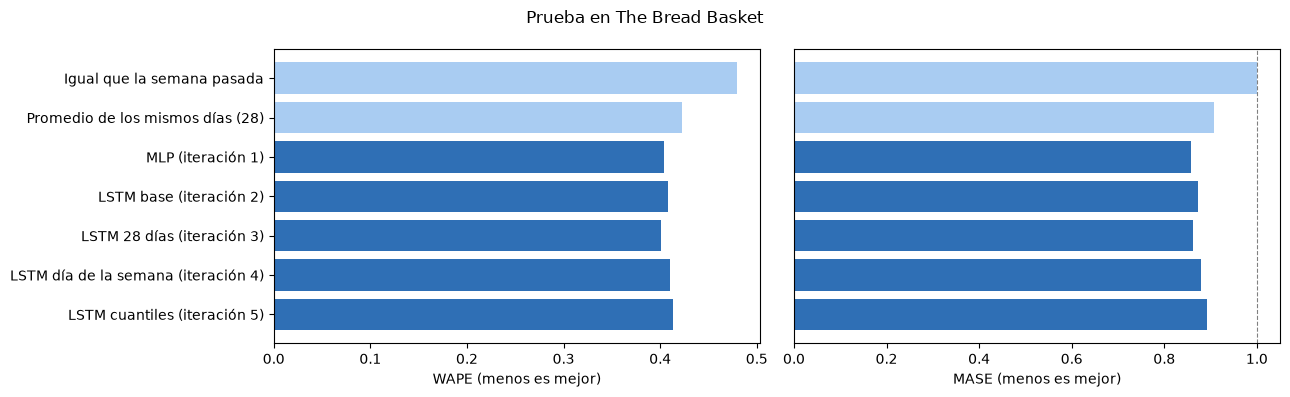

In [8]:
plot_results(bb_results, "Prueba en The Bread Basket")

**Pregunta 2: el día de la semana.** La iteración 4 es igual a la 2 salvo por el día de la semana, así que su diferencia mide solo el efecto de esa variable. En validación (negocios con pico el domingo) la iteración 4 fue mejor.

In [9]:
bb_results.loc[["LSTM base (iteración 2)", "LSTM día de la semana (iteración 4)"], ["MAE", "WAPE", "MASE"]].round(3)

,MAE,WAPE,MASE
LSTM base (iteración 2),2.285,0.408,0.873
LSTM día de la semana (iteración 4),2.296,0.410,0.879


Para ver dónde aparece la diferencia, se compara el error de cada modelo por día de la semana que se predice.

In [10]:
keep = (test_w.meta["dataset"] == "bread_basket").to_numpy()
sub = make_subset(test_w, keep)
scale = sub.scale[:, None]
first = pd.to_datetime(sub.meta["first_date"]).to_numpy()
days = pd.DatetimeIndex((first[:, None] + pd.to_timedelta(range(7), unit="D").to_numpy()[None, :]).ravel())
mask = sub.mask.ravel() == 1
actual = (sub.target * scale).ravel()

by_day = {}
for name in ["Promedio de los mismos días (28)", "LSTM base (iteración 2)", "LSTM día de la semana (iteración 4)"]:
    error = pd.Series(abs((test_preds[name][keep] * scale).ravel() - actual)[mask], index=days[mask].day_name())
    by_day[name] = error.groupby(level=0).sum() / pd.Series(actual[mask], index=days[mask].day_name()).groupby(level=0).sum()
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
pd.DataFrame(by_day).loc[order].round(3)

,Promedio de los mismos días (28),LSTM base (iteración 2),LSTM día de la semana (iteración 4)
Monday,0.503,0.447,0.451
Tuesday,0.405,0.429,0.438
Wednesday,0.435,0.411,0.420
Thursday,0.465,0.417,0.423
Friday,0.368,0.354,0.347
Saturday,0.356,0.370,0.358
Sunday,0.495,0.469,0.485


**Por producto.** WAPE de la mejor línea base y del LSTM de 28 días en cada producto, junto con su venta promedio diaria.

In [11]:
by_product = {}
for name in ["Promedio de los mismos días (28)", "LSTM 28 días (iteración 3)"]:
    table = evaluate(sub, test_preds[name][keep], naive_all[keep], by=("product_id",))
    by_product[name] = table["WAPE"].drop(index="Total")
bb_scale = df[(df["dataset"] == "bread_basket") & df["is_open"]].groupby("product_id")["sales"].mean().rename("venta promedio diaria")
products = pd.DataFrame(by_product).join(bb_scale)
products["mejora"] = 1 - products["LSTM 28 días (iteración 3)"] / products["Promedio de los mismos días (28)"]
products.index = products.index.str.replace("bread_basket_", "")
products.sort_values("venta promedio diaria", ascending=False).round(3)

,Promedio de los mismos días (28),LSTM 28 días (iteración 3),venta promedio diaria,mejora
product_id,,,,
coffee,0.213,0.201,34.409,0.057
bread,0.271,0.244,20.912,0.097
tea,0.367,0.360,9.025,0.018
cake,0.451,0.448,6.447,0.005
pastry,0.486,0.451,5.384,0.071
sandwich,0.490,0.480,4.880,0.020
medialuna,0.610,0.608,3.874,0.003
hot_chocolate,0.556,0.547,3.711,0.016
cookies,0.555,0.546,3.396,0.016


**Pregunta 3: calibración.** Para cada cuantil de la iteración 5, el porcentaje de días en que la venta real quedó por debajo de lo predicho. En validación la diferencia máxima fue de 1.3 puntos.

In [12]:
q_pred = test_full["LSTM cuantiles (iteración 5)"][keep] * sub.scale[:, None, None]
real = sub.target * sub.scale[:, None]
calibration_bb = pd.DataFrame({
    "cuantil": QUANTILES,
    "cobertura real": [(real[sub.mask == 1] <= q_pred[..., i][sub.mask == 1]).mean() for i in range(len(QUANTILES))],
})
calibration_bb["diferencia"] = calibration_bb["cobertura real"] - calibration_bb["cuantil"]
calibration_bb.round(3)

,cuantil,cobertura real,diferencia
0,0.50,0.597,0.097
1,0.55,0.637,0.087
2,0.60,0.669,0.069
3,0.65,0.704,0.054
4,0.70,0.737,0.037
5,0.75,0.767,0.017
6,0.80,0.803,0.003
7,0.85,0.838,-0.012
8,0.90,0.881,-0.019


**Conclusiones de la prueba en The Bread Basket:**

- **Las redes le ganan a las líneas base en un negocio distinto al del entrenamiento.** El LSTM de 28 días se equivoca por 2.25 unidades al día (WAPE 40.1 %, MASE 0.86), frente a 2.37 de la mejor línea base (42.3 %). Es el mejor modelo en validación, en ddop y aquí, y mejora en 18 de los 20 productos.
- **El WAPE es alto por la escala, no por el modelo:** The Bread Basket vende unas 2.6 unidades al día por producto, y en los productos más pequeños (Brownie, Muffin, Fudge, Alfajores) el error supera lo vendido porque muchos días venden 0 o 1.
- **El día de la semana empeora un poco en este negocio** (41.0 % contra 40.8 % del LSTM base), al revés que en validación. El peor empeoramiento es el domingo (48.5 % contra 46.9 %): lo más probable es que el modelo aprendiera de ddop y French Bakery que el domingo se vende más, cuando aquí el pico es el sábado. La diferencia es pequeña, así que es un indicio consistente con la hipótesis, no una prueba definitiva, y respalda no haber usado el día de la semana en la iteración 5.
- **Los cuantiles altos siguen calibrados** (del 0.75 al 0.90, a 2 puntos o menos), que es justo donde están los q* de los productos. Los cuantiles bajos cubren de más (la mediana cubre el 60 % de los días) porque las ventas son enteros pequeños con muchos ceros; afecta poco a las decisiones, porque casi ningún producto usa cuantiles por debajo de 0.70.

## **3. Prueba de temporada**

Julio a septiembre de 2022 en French Bakery: un negocio que el modelo sí conoce, pero en pleno pico turístico, cuando las ventas casi se duplican. Mide cuánto sufre cada modelo con un cambio brusco de nivel, la limitación que se anticipó en el análisis exploratorio. Se compara además contra su error en validación (abril a junio, temporada normal).

In [13]:
season_w, season_preds, season_full = predictions_for(["test_season"])
naive_all = season_preds["Igual que la semana pasada"]
season_results = results_table(season_w, season_preds, "french_bakery")
naive_all = naive  # se restaura la línea base de la prueba principal
season_results.round(3)

,MAE,RMSE,WAPE,MAE relativo,MASE
Igual que la semana pasada,6.071,17.534,0.346,1.000,1.000
Promedio de los mismos días (28),7.449,24.512,0.424,1.227,1.021
MLP (iteración 1),5.472,17.306,0.312,0.901,0.855
LSTM base (iteración 2),5.448,16.997,0.310,0.897,0.859
LSTM 28 días (iteración 3),5.856,18.566,0.334,0.965,0.880
LSTM día de la semana (iteración 4),5.285,16.408,0.301,0.870,0.845
LSTM cuantiles (iteración 5),5.718,18.200,0.326,0.942,0.867


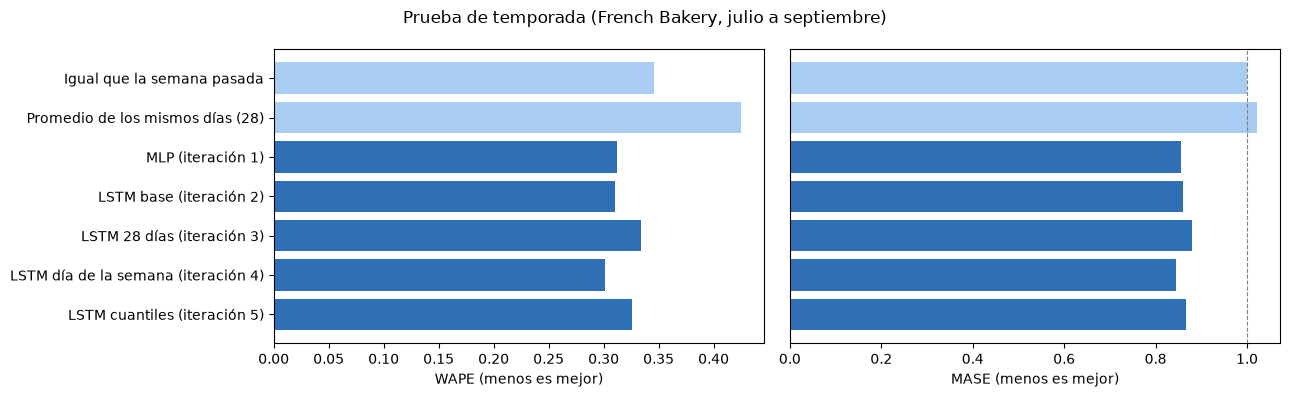

In [14]:
plot_results(season_results, "Prueba de temporada (French Bakery, julio a septiembre)")

Comparación del WAPE de cada modelo en French Bakery entre la validación (temporada normal) y la prueba de temporada (pico de verano):

In [15]:
val_fb = {}
for name, (model, _, lookback, dow) in models.items():
    w = make_windows(df, lookback, ["val"], use_day_of_week=dow, first_offset=28)
    keep_fb = (w.meta["dataset"] == "french_bakery").to_numpy()
    sub_fb = make_subset(w, keep_fb)
    ref = make_windows(df, 28, ["val"], first_offset=28)
    val_fb[name] = evaluate(sub_fb, predict(model, w)[..., 0][keep_fb], seasonal_naive(ref)[keep_fb]).loc[("Total", ""), "WAPE"]
ref = make_windows(df, 28, ["val"], first_offset=28)
keep_fb = (ref.meta["dataset"] == "french_bakery").to_numpy()
sub_fb = make_subset(ref, keep_fb)
for name, fn in [("Igual que la semana pasada", seasonal_naive), ("Promedio de los mismos días (28)", same_weekday_mean)]:
    val_fb[name] = evaluate(sub_fb, fn(ref)[keep_fb], seasonal_naive(ref)[keep_fb]).loc[("Total", ""), "WAPE"]

season_compare = pd.DataFrame({"validación (abril a junio)": pd.Series(val_fb), "temporada (julio a septiembre)": season_results["WAPE"]})
season_compare["aumento"] = season_compare["temporada (julio a septiembre)"] - season_compare["validación (abril a junio)"]
season_compare.loc[season_results.index].round(3)

,validación (abril a junio),temporada (julio a septiembre),aumento
Igual que la semana pasada,0.489,0.346,-0.143
Promedio de los mismos días (28),0.398,0.424,0.026
MLP (iteración 1),0.350,0.312,-0.038
LSTM base (iteración 2),0.342,0.310,-0.032
LSTM 28 días (iteración 3),0.338,0.334,-0.004
LSTM día de la semana (iteración 4),0.338,0.301,-0.037
LSTM cuantiles (iteración 5),0.338,0.326,-0.012


El cambio de nivel no ocurre igual todo el periodo: el salto fuerte es al inicio de julio y la caída al final de agosto. La siguiente gráfica muestra el WAPE semana a semana del mejor modelo y de la mejor línea base, junto con las ventas totales.

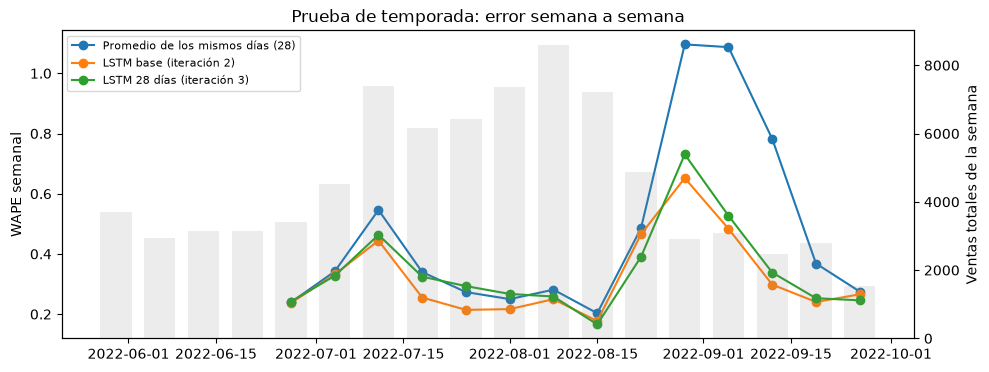

In [16]:
sub_s = season_w
scale_s = sub_s.scale[:, None]
first_s = pd.to_datetime(sub_s.meta["first_date"]).to_numpy()
days_s = pd.DatetimeIndex((first_s[:, None] + pd.to_timedelta(range(7), unit="D").to_numpy()[None, :]).ravel())
mask_s = sub_s.mask.ravel() == 1
actual_s = (sub_s.target * scale_s).ravel()
weeks = days_s[mask_s].to_period("W").start_time

weekly = {}
for name in ["Promedio de los mismos días (28)", "LSTM base (iteración 2)", "LSTM 28 días (iteración 3)"]:
    error = pd.Series(abs((season_preds[name] * scale_s).ravel() - actual_s)[mask_s], index=weeks)
    weekly[name] = error.groupby(level=0).sum() / pd.Series(actual_s[mask_s], index=weeks).groupby(level=0).sum()
weekly = pd.DataFrame(weekly)
sales = df[(df["dataset"] == "french_bakery") & (df["date"] >= "2022-06-01")].groupby(pd.Grouper(key="date", freq="W-MON", label="left"))["sales"].sum()

fig, ax = plt.subplots(figsize=(11, 4))
for name in weekly.columns:
    ax.plot(weekly.index, weekly[name], marker="o", label=name)
ax.set_ylabel("WAPE semanal")
ax2 = ax.twinx()
ax2.bar(sales.index, sales.values, width=5, alpha=0.15, color="gray", label="ventas totales")
ax2.set_ylabel("Ventas totales de la semana")
ax.set_title("Prueba de temporada: error semana a semana")
ax.legend(loc="upper left", fontsize=8)
plt.show()

**Conclusiones de la prueba de temporada:**

- **Todas las redes le ganan a "igual que la semana pasada" cuando cambia la temporada,** y por más margen las de ventana de 14 días: la iteración 4 tiene un MAE relativo de 0.87, el LSTM base 0.90 y la MLP 0.90, frente a 0.97 del LSTM de 28 días y 0.94 de la iteración 5. La mejor línea base queda peor que copiar la semana anterior (1.23).
- **La ventana corta se adapta más rápido a un cambio brusco de nivel,** que era lo que se esperaba desde el análisis exploratorio: con 14 días, las semanas viejas de otra temporada salen antes de la ventana. Es el costo de la ventana de 28 días, que es la mejor en temporada normal (validación y prueba principal).
- **El momento más difícil es el final del verano,** no el inicio: cuando las ventas caen a la mitad a fines de agosto, las ventanas siguen llenas de semanas altas y todos los modelos predicen de más; las redes de 14 días se recuperan algo antes.
- **Para comparar entre periodos se usa el MAE relativo,** no el WAPE: en verano el negocio vende más, y el mismo error pesa menos en porcentaje.

## **4. Supuestos de precios y costos**

The Bread Basket no trae precios ni costos, así que el valor en dinero se calcula con supuestos documentados en `data/value_assumptions.csv`:

- **Precio de venta:** para Sandwich y Muffin, el precio oficial de la ONS (oficina de estadística de Reino Unido) en Escocia en 2016-2017. Para el resto, menús y proveedores ajustados a 2017 con el índice de precios de cafeterías de la ONS, o estimaciones por comparación con productos parecidos.
- **Costo:** solo ingredientes, sin mano de obra, como porcentaje del precio según guías de costeo de la industria (Sage, Xlent Foods y fichas de receta del mayorista Booker).
- **Lo que sobra se tira** (valor de rescate 0).

Con eso, para cada producto:

- **Cu** (cuesta que falte) = precio − costo: el margen que se pierde.
- **Co** (cuesta que sobre) = costo: los ingredientes que se tiran.
- **q\*** = Cu / (Cu + Co) = 1 − porcentaje de costo: el cuantil que conviene producir. Mientras más barato es producir algo, más conviene que sobre a que falte.

Solo entran los 15 productos que se producen por adelantado. Coffee, Tea, Hot chocolate y Toast se preparan al momento, y Juice se compra y dura varios días, así que no se tiran al final del día.

In [17]:
from src.value import load_assumptions, newsvendor_cost, produce, quantile_choice

ASSUMPTIONS = ROOT / "data" / "value_assumptions.csv"
assumptions = load_assumptions(ASSUMPTIONS)
assumptions[["producto", "tipo", "precio", "costo_pct", "costo", "Cu", "Co", "q_star", "fuente_precio", "fuente_costo"]].round(2)

,producto,tipo,precio,costo_pct,costo,Cu,Co,q_star,fuente_precio,fuente_costo
product_id,,,,,,,,,,
bread_basket_bread,Bread,Pan,2.00,0.25,0.50,1.50,0.50,0.75,Estimado (piso: ONS hogaza de supermercado £1....,Guías de costeo de panadería: pan 15-30 %
bread_basket_farm_house,Farm House,Pan,2.20,0.25,0.55,1.65,0.55,0.75,Estimado (mismo piso ONS),Guías de costeo de panadería: pan 15-30 %
bread_basket_pastry,Pastry,Bollería,1.80,0.30,0.54,1.26,0.54,0.70,Menús y cadenas ajustados a 2017 con el índice...,Sage y Xlent Foods: bollería 25-30 %
bread_basket_medialuna,Medialuna,Bollería,1.20,0.30,0.36,0.84,0.36,0.70,Estimado (más pequeña que un croissant),Sage y Xlent Foods: bollería 25-30 %
bread_basket_scandinavian,Scandinavian,Bollería,2.20,0.30,0.66,1.54,0.66,0.70,Menús y proveedores ajustados a 2017 con el ín...,Sage y Xlent Foods: bollería 25-30 %
bread_basket_cake,Cake,Pastel,2.30,0.28,0.64,1.66,0.64,0.72,Menús y proveedores ajustados a 2017 con el ín...,Sage y Xlent Foods: pasteles 25-30 %
bread_basket_brownie,Brownie,Pastel,1.80,0.28,0.50,1.30,0.50,0.72,Menús y proveedores ajustados a 2017 con el ín...,Booker: receta de brownie 27-28 %
bread_basket_muffin,Muffin,Pastel,1.80,0.28,0.50,1.30,0.50,0.72,ONS Escocia 2016-17: muffin o pastel individual,Sage y Xlent Foods: pasteles 25-30 %
bread_basket_scone,Scone,Pastelería,2.00,0.20,0.40,1.60,0.40,0.80,Menús y proveedores ajustados a 2017 con el ín...,Booker: receta de scone 16 %


## **5. Regla de redondeo, decidida con la validación**

Para producir hay que convertir cada predicción en unidades enteras, y la regla importa mucho cuando se venden 2 o 3 unidades al día. Hay tres opciones: redondear hacia arriba, hacia abajo o al entero más cercano. Por ejemplo, redondear hacia arriba agrega un margen de seguridad a una predicción del valor medio, pero sobre un cuantil que ya apunta alto puede hacer que sobre demasiado.

Como cualquier otra decisión, la regla se elige con la validación y no con la prueba: cada modelo usa la regla que le da menor costo en la validación de French Bakery (abril a junio de 2022), y esa regla se respeta en la prueba sin cambiarla. French Bakery trae precios de venta reales; el costo de cada producto se asigna con el mismo porcentaje por tipo que en The Bread Basket (pan 25 %, bollería y galletas 30 %, pasteles 28 %, comida preparada 35 %).

In [18]:
import numpy as np
from src.value import load_assumptions, newsvendor_cost, produce, quantile_choice

ROUNDING = {"hacia arriba": np.ceil, "al más cercano": np.round, "hacia abajo": np.floor}
FB_TYPES = {
    0.25: ["baguette", "banette", "banettine", "boule_200g", "boule_400g", "boule_polka", "campagne", "cereal_baguette", "complet",
           "demi_baguette", "ficelle", "moisson", "pain", "pain_banette", "quim_bread", "seigle", "special_bread", "special_bread_kg",
           "traditional_baguette", "vik_bread"],
    0.30: ["brioche", "chausson_aux_pommes", "croissant", "croissant_amandes", "gd_kouign_amann", "kouign_amann", "pain_au_chocolat",
           "pain_aux_raisins", "pain_choco_amandes", "sachet_viennoiserie", "paille", "pt_nantais", "cookie"],
    0.28: ["eclair", "financier_x5", "flan", "flan_abricot", "fondant_chocolat", "grand_far_breton", "milles_feuilles", "paris_brest", "tartelette"],
    0.35: ["formule_sandwich", "sand_jb_emmental", "sandwich_complet", "traiteur", "plat_7.60e"],
}
fb_cost_pct = {f"french_bakery_{name}": pct for pct, names in FB_TYPES.items() for name in names}

raw_fb = pd.read_csv(ROOT / "data" / "raw" / "french_bakery" / "bakery_sales.csv", index_col=0)
raw_fb["price"] = raw_fb["unit_price"].str.replace("€", "", regex=False).str.replace(",", ".", regex=False).str.strip().astype(float)
raw_fb["product_id"] = "french_bakery_" + raw_fb["article"].str.lower().str.replace(" ", "_", regex=False)
fb_assumptions = (
    raw_fb.groupby("product_id")["price"].median().rename("precio").to_frame()
    .join(pd.Series(fb_cost_pct, name="costo_pct"), how="inner")
)
fb_assumptions["Cu"] = fb_assumptions["precio"] * (1 - fb_assumptions["costo_pct"])
fb_assumptions["Co"] = fb_assumptions["precio"] * fb_assumptions["costo_pct"]
fb_assumptions["q_star"] = 1 - fb_assumptions["costo_pct"]
print(f"Productos de French Bakery con precio y costo: {len(fb_assumptions)}")

Productos de French Bakery con precio y costo: 47


In [19]:
val_w, val_preds, val_full = predictions_for(["val"])
fb_rows = (val_w.meta["dataset"] == "french_bakery").to_numpy() & val_w.meta["product_id"].isin(fb_assumptions.index).to_numpy()
fb = make_subset(val_w, fb_rows)
fb_scale = fb.scale[:, None]
fb_actual = (fb.target * fb_scale)[:, 0]
fb_mask = fb.mask[:, 0] == 1
fb_a = fb_assumptions.loc[fb.meta["product_id"]]

rule_costs = {}
for name, prediction in val_preds.items():
    if name == "LSTM cuantiles (iteración 5)":
        ladder = val_full[name][fb_rows] * fb_scale[..., None]
        continuous = quantile_choice(ladder, QUANTILES, fb_a["q_star"].to_numpy())[:, 0]
    else:
        continuous = prediction[fb_rows][:, 0] * fb_scale[:, 0]
    rule_costs[name] = {}
    for rule, fn in ROUNDING.items():
        cost, _, _ = newsvendor_cost(produce(continuous, fn), fb_actual, fb_a["Cu"].to_numpy(), fb_a["Co"].to_numpy())
        rule_costs[name][rule] = cost[fb_mask].sum()

rule_costs = pd.DataFrame(rule_costs).T
rule_costs["regla elegida"] = rule_costs.idxmin(axis=1)
RULES = rule_costs["regla elegida"].to_dict()
rule_costs.round(0)

,hacia arriba,al más cercano,hacia abajo,regla elegida
Igual que la semana pasada,17405.0,17418.0,17691.0,hacia arriba
Promedio de los mismos días (28),14201.0,14777.0,15649.0,hacia arriba
MLP (iteración 1),12973.0,13492.0,14457.0,hacia arriba
LSTM base (iteración 2),12545.0,13173.0,13962.0,hacia arriba
LSTM 28 días (iteración 3),12790.0,13479.0,14596.0,hacia arriba
LSTM día de la semana (iteración 4),12439.0,13003.0,14075.0,hacia arriba
LSTM cuantiles (iteración 5),11694.0,11521.0,11710.0,al más cercano


Las líneas base y las iteraciones 1 a 4 redondean hacia arriba: a una predicción del valor medio le conviene una unidad extra, porque faltar cuesta más que sobrar. La iteración 5 redondea al entero más cercano, porque su escalón ya apunta al cuantil que conviene producir. Estas reglas se aplican tal cual en la prueba.

## **6. Valor en dinero: decisión diaria**

Cada tarde se corre el modelo y se usa su predicción del día siguiente (el día 1 del horizonte) para decidir cuánto producir. Así se aprovecha siempre la información más reciente y cada día se cuenta una sola vez.

- **Líneas base e iteraciones 1 a 4:** se produce su predicción, con la regla de redondeo elegida en validación.
- **Iteración 5:** se produce el escalón más cercano al q* de cada producto, con su regla de redondeo.
- **Costo de cada día:** unidades faltantes × Cu + unidades sobrantes × Co, solo en días abiertos.

La cifra principal es el **ahorro mensual frente a la mejor línea base** (promedio de los mismos días).

In [20]:
assumptions = load_assumptions(ROOT / "data" / "value_assumptions.csv")
bb_keep = (test_w.meta["dataset"] == "bread_basket").to_numpy() & test_w.meta["product_id"].isin(assumptions.index).to_numpy()
bb = make_subset(test_w, bb_keep)
bb_scale = bb.scale[:, None]
bb_actual = bb.target * bb_scale
bb_a = assumptions.loc[bb.meta["product_id"]]


def production_plans(a=bb_a, interpolate=False):
    """Unidades a producir por cada modelo para cada ejemplo y día del horizonte, con su regla de redondeo."""
    plans = {}
    for name, prediction in test_preds.items():
        if name == "LSTM cuantiles (iteración 5)":
            ladder = test_full[name][bb_keep] * bb_scale[..., None]
            continuous = quantile_choice(ladder, QUANTILES, a["q_star"].to_numpy(), interpolate)
        else:
            continuous = prediction[bb_keep] * bb_scale
        plans[name] = produce(continuous, ROUNDING[RULES[name]])
    return plans


def money_table(plans, horizons, rows, a=bb_a):
    """Costo y ahorro mensual de cada modelo usando los días del horizonte indicados."""
    mask = bb.mask[rows][:, horizons] == 1
    actual = bb_actual[rows][:, horizons]
    cu, co = a["Cu"].to_numpy()[rows][:, None], a["Co"].to_numpy()[rows][:, None]
    months = bb.meta.loc[rows, "first_date"].nunique() / 30.44
    out = {}
    for name, plan in plans.items():
        cost, short, left = newsvendor_cost(plan[rows][:, horizons], actual, cu, co)
        out[name] = {
            "costo por mes (£)": cost[mask].sum() / months,
            "unidades faltantes": short[mask].sum(),
            "unidades sobrantes": left[mask].sum(),
            "nivel de servicio": 1 - short[mask].sum() / actual[mask].sum(),
        }
    table = pd.DataFrame(out).T
    base = table.loc["Promedio de los mismos días (28)", "costo por mes (£)"]
    table["ahorro por mes (£)"] = base - table["costo por mes (£)"]
    table["ahorro (%)"] = table["ahorro por mes (£)"] / base
    return table


plans = production_plans()
all_rows = np.ones(len(bb), dtype=bool)
daily = money_table(plans, [0], all_rows)
print(f"Periodo evaluado: {bb.meta['first_date'].nunique()} días ({bb.meta['first_date'].nunique() / 30.44:.1f} meses), {bb.meta['product_id'].nunique()} productos")
daily.round(3)

Periodo evaluado: 128 días (4.2 meses), 15 productos


,costo por mes (£),unidades faltantes,unidades sobrantes,nivel de servicio,ahorro por mes (£),ahorro (%)
Igual que la semana pasada,962.892,2114.0,2238.0,0.709,-160.692,-0.200
Promedio de los mismos días (28),802.200,1458.0,2637.0,0.799,0.000,0.000
MLP (iteración 1),750.741,1444.0,2264.0,0.801,51.460,0.064
LSTM base (iteración 2),744.506,1371.0,2404.0,0.811,57.695,0.072
LSTM 28 días (iteración 3),734.566,1341.0,2403.0,0.815,67.635,0.084
LSTM día de la semana (iteración 4),744.397,1393.0,2325.0,0.808,57.803,0.072
LSTM cuantiles (iteración 5),743.645,903.0,3684.0,0.875,58.555,0.073


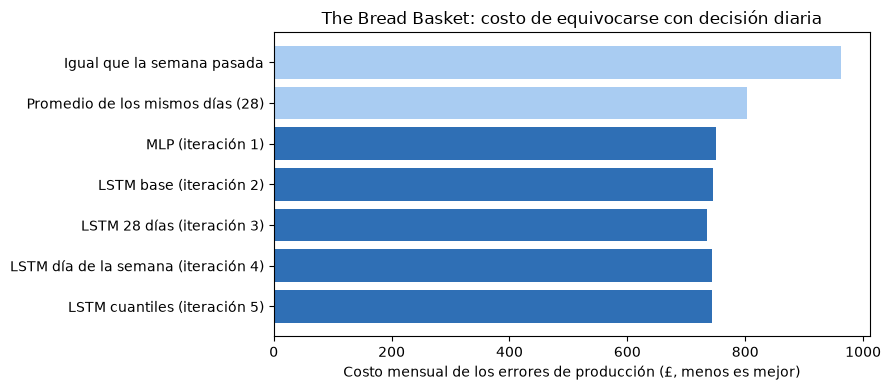

In [21]:
fig, ax = plt.subplots(figsize=(9, 4))
colors = ["#a9ccf2"] * 2 + ["#2f6fb5"] * (len(daily) - 2)
ax.barh(daily.index[::-1], daily["costo por mes (£)"][::-1], color=colors[::-1])
ax.set_xlabel("Costo mensual de los errores de producción (£, menos es mejor)")
ax.set_title("The Bread Basket: costo de equivocarse con decisión diaria")
plt.tight_layout()
plt.show()

**Conclusiones del valor en dinero:**

- **Todas las redes ahorran frente a la mejor línea base,** entre £51 y £68 al mes en los 15 productos que The Bread Basket produce por adelantado. La iteración 3 ahorra £68 al mes (8.4 % del costo de equivocarse) y la 5 £59 (7.3 %).
- **La iteración 5 ahorra parecido por otro camino:** falta un tercio menos de producto y atiende el 88 % de la demanda (contra 82 %), a cambio de que sobre más. En la validación de French Bakery, con más volumen por producto, es la más barata (unos 10 % menos que la iteración 3); con ventas de 2 o 3 unidades al día, la diferencia entre la mediana más una unidad y el escalón q* casi desaparece.
- **La app usa la iteración 5,** porque además del ahorro da un rango de incertidumbre para mostrar al usuario y recomienda producir según los costos de cada negocio.

## **7. Error por día del horizonte**

El modelo predice los 7 días siguientes de una vez y se vuelve a correr cada día. La app destaca el día siguiente y muestra los 7 días como referencia; esta tabla mide cuánto se pierde de precisión al mirar más lejos.

In [22]:
horizon = {}
keep_bb = (test_w.meta["dataset"] == "bread_basket").to_numpy()
sub_bb = make_subset(test_w, keep_bb)
for name in ["Promedio de los mismos días (28)", "LSTM 28 días (iteración 3)", "LSTM cuantiles (iteración 5)"]:
    pred = test_preds[name][keep_bb] * sub_bb.scale[:, None]
    actual = sub_bb.target * sub_bb.scale[:, None]
    open_ = sub_bb.mask == 1
    horizon[name] = [np.abs(pred[:, h] - actual[:, h])[open_[:, h]].sum() / actual[:, h][open_[:, h]].sum() for h in range(7)]
horizon = pd.DataFrame(horizon, index=[f"día {h + 1}" for h in range(7)])
horizon.round(3)

,Promedio de los mismos días (28),LSTM 28 días (iteración 3),LSTM cuantiles (iteración 5)
día 1,0.427,0.396,0.408
día 2,0.427,0.401,0.413
día 3,0.424,0.399,0.412
día 4,0.423,0.402,0.416
día 5,0.422,0.406,0.418
día 6,0.419,0.401,0.408
día 7,0.420,0.404,0.418


**Conclusión:** el error casi no crece con la distancia: el LSTM de 28 días pasa de 39.6 % el día siguiente a 40.4 % a siete días, y la iteración 5 de 40.8 % a 41.8 %. Por eso la app puede mostrar los 7 días con confianza, destacando el día siguiente, que es el que se usa para decidir la producción.

## **8. Curva de valor**

La curva de valor responde: **¿qué cuantil conviene producir?** Se toma la escalera de la iteración 5 y, en lugar de usar el q* de cada producto, se obliga a todos los productos a producir el mismo escalón, del 0.50 al 0.90, y se calcula el costo mensual con cada uno. Si producir el valor medio (0.50) fuera lo mejor, la curva tendría su mínimo ahí; si conviene producir de más, el mínimo estará más arriba. Se marcan como referencia el costo de la mejor línea base y el de usar el q* de cada producto.

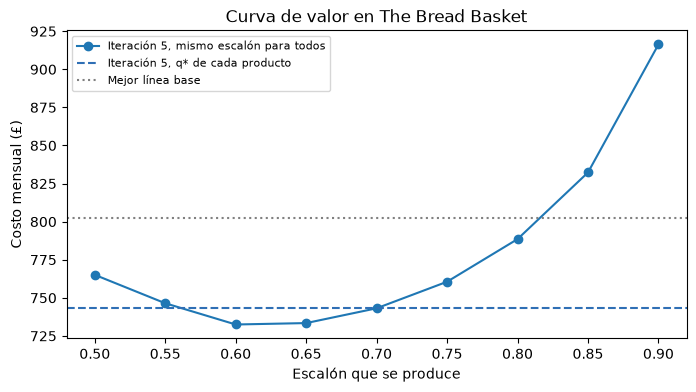

,costo por mes (£),nivel de servicio
escalón para todos los productos,,
0.50,765.089,0.782
0.55,746.437,0.806
0.60,732.494,0.831
0.65,733.422,0.851
0.70,743.135,0.870
0.75,760.566,0.886
0.80,788.541,0.906
0.85,832.285,0.925
0.90,916.301,0.943


In [23]:
ladder = test_full["LSTM cuantiles (iteración 5)"][bb_keep] * bb_scale[..., None]
cu_all, co_all = bb_a["Cu"].to_numpy()[:, None], bb_a["Co"].to_numpy()[:, None]
day_mask = bb.mask[:, [0]] == 1
months = bb.meta["first_date"].nunique() / 30.44

curve = {}
for i, q in enumerate(QUANTILES):
    plan = produce(ladder[:, [0], i], ROUNDING[RULES["LSTM cuantiles (iteración 5)"]])
    cost, short, left = newsvendor_cost(plan, bb_actual[:, [0]], cu_all, co_all)
    curve[q] = {"costo por mes (£)": cost[day_mask].sum() / months, "nivel de servicio": 1 - short[day_mask].sum() / bb_actual[:, [0]][day_mask].sum()}
curve = pd.DataFrame(curve).T
curve.index.name = "escalón para todos los productos"

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(curve.index, curve["costo por mes (£)"], marker="o", label="Iteración 5, mismo escalón para todos")
ax.axhline(daily.loc["LSTM cuantiles (iteración 5)", "costo por mes (£)"], color="#2f6fb5", linestyle="--", label="Iteración 5, q* de cada producto")
ax.axhline(daily.loc["Promedio de los mismos días (28)", "costo por mes (£)"], color="gray", linestyle=":", label="Mejor línea base")
ax.set_xlabel("Escalón que se produce")
ax.set_ylabel("Costo mensual (£)")
ax.set_title("Curva de valor en The Bread Basket")
ax.legend(fontsize=8)
plt.show()
curve.round(3)

**Conclusión:** producir el valor medio (escalón 0.50) no es lo que más conviene: cuesta £765 al mes, y subir a los escalones 0.60 o 0.65 lo baja a unos £733. El punto de operación óptimo está por encima de la mediana porque quedarse corto cuesta más que pasarse, que es justo la idea del newsvendor. Pasado el 0.70 el costo vuelve a subir, porque sobra demasiado. En The Bread Basket el óptimo cae algo por debajo del q* de los productos (0.65 a 0.80), coherente con que en este negocio los cuantiles bajos y medios de la red cubren de más por las ventas enteras y pequeñas.

La curva de valor también se puede ver desde la métrica técnica: ¿cuando un modelo predice mejor, ahorra más? Para cada modelo se grafica su WAPE contra su ahorro mensual frente a la mejor línea base. Ambos se calculan sobre lo mismo: los 15 productos que se producen por adelantado y la predicción del día siguiente.

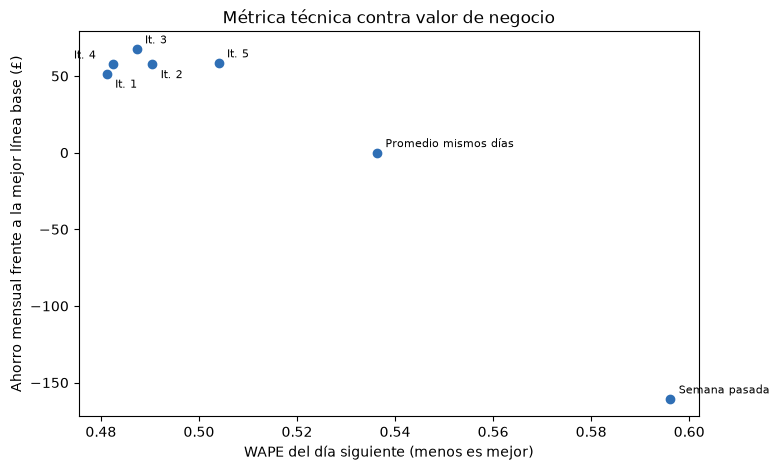

,WAPE,ahorro por mes (£)
Igual que la semana pasada,0.596,-160.692
Promedio de los mismos días (28),0.536,0.000
MLP (iteración 1),0.481,51.460
LSTM base (iteración 2),0.491,57.695
LSTM 28 días (iteración 3),0.487,67.635
LSTM día de la semana (iteración 4),0.482,57.803
LSTM cuantiles (iteración 5),0.504,58.555


In [24]:
tech_vs_value = {}
open_day1 = bb.mask[:, 0] == 1
actual_day1 = bb_actual[:, 0]
for name, prediction in test_preds.items():
    pred_day1 = prediction[bb_keep][:, 0] * bb_scale[:, 0]
    tech_vs_value[name] = {
        "WAPE": np.abs(pred_day1 - actual_day1)[open_day1].sum() / actual_day1[open_day1].sum(),
        "ahorro por mes (£)": daily.loc[name, "ahorro por mes (£)"],
    }
tech_vs_value = pd.DataFrame(tech_vs_value).T

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(tech_vs_value["WAPE"], tech_vs_value["ahorro por mes (£)"], color="#2f6fb5")
short = {"Igual que la semana pasada": "Semana pasada", "Promedio de los mismos días (28)": "Promedio mismos días",
         "MLP (iteración 1)": "It. 1", "LSTM base (iteración 2)": "It. 2", "LSTM 28 días (iteración 3)": "It. 3",
         "LSTM día de la semana (iteración 4)": "It. 4", "LSTM cuantiles (iteración 5)": "It. 5"}
offsets = {"It. 1": (6, -10), "It. 2": (6, -10), "It. 3": (6, 4), "It. 4": (-28, 4), "It. 5": (6, 4)}
for name, row in tech_vs_value.iterrows():
    label = short[name]
    ax.annotate(label, (row["WAPE"], row["ahorro por mes (£)"]), fontsize=8, xytext=offsets.get(label, (6, 4)), textcoords="offset points")
ax.set_xlabel("WAPE del día siguiente (menos es mejor)")
ax.set_ylabel("Ahorro mensual frente a la mejor línea base (£)")
ax.set_title("Métrica técnica contra valor de negocio")
plt.show()
tech_vs_value.round(3)

**Conclusión:** de las líneas base a las redes, predecir mejor sí se traduce en dinero: bajar el WAPE del día siguiente de 53.6 % a menos de 50.5 % significa ahorrar entre £51 y £68 al mes. Pero entre las redes, que están a menos de 2 puntos de WAPE entre sí, el orden ya no coincide: la MLP tiene el menor WAPE (48.1 %) y es la que menos ahorra (£51), mientras que la iteración 5 tiene el mayor WAPE de las redes (50.4 %) y ahorra casi lo mismo que la mejor. Cuando los modelos predicen parecido, lo que más pesa en el dinero es cómo se decide cuánto producir, no la precisión.

## **9. Análisis de sensibilidad**

Los precios y costos de The Bread Basket son supuestos. Esta sección cambia cada supuesto, uno a la vez, y recalcula el ahorro mensual de las iteraciones 3 y 5 frente a la mejor línea base. Al cambiar los costos también cambia el q* de cada producto, así que la iteración 5 elige otros escalones.

- **Costo de ingredientes:** ±20 % y ±50 %.
- **Precio de venta,** con el costo fijo: ±20 % y ±50 %.
- **Valor de rescate:** que lo que sobra se recupere en un 10 % o 30 % del precio, por ejemplo vendiéndolo a menor precio al día siguiente.

In [25]:
def savings(cost_factor=1.0, price_factor=1.0, salvage_pct=0.0):
    a = load_assumptions(ROOT / "data" / "value_assumptions.csv", cost_factor, price_factor, salvage_pct).loc[bb.meta["product_id"]]
    table = money_table(production_plans(a), [0], all_rows, a)
    return table.loc[["LSTM 28 días (iteración 3)", "LSTM cuantiles (iteración 5)"], "ahorro por mes (£)"]


scenarios = {"Supuestos base": {}}
for f in (0.5, 0.8, 1.2, 1.5):
    scenarios[f"Costo {f - 1:+.0%}"] = {"cost_factor": f}
for f in (0.5, 0.8, 1.2, 1.5):
    scenarios[f"Precio {f - 1:+.0%}"] = {"price_factor": f}
for s in (0.1, 0.3):
    scenarios[f"Rescate {s:.0%}"] = {"salvage_pct": s}
sensitivity = pd.DataFrame({name: savings(**kwargs) for name, kwargs in scenarios.items()}).T
sensitivity.round(1)

,LSTM 28 días (iteración 3),LSTM cuantiles (iteración 5)
Supuestos base,67.6,58.6
Costo -50%,63.1,193.6
Costo -20%,65.8,89.6
Costo +20%,69.4,41.5
Costo +50%,72.2,66.0
Precio -50%,38.4,59.2
Precio -20%,55.9,35.3
Precio +20%,79.3,97.1
Precio +50%,96.9,189.2
Rescate 10%,57.8,100.6


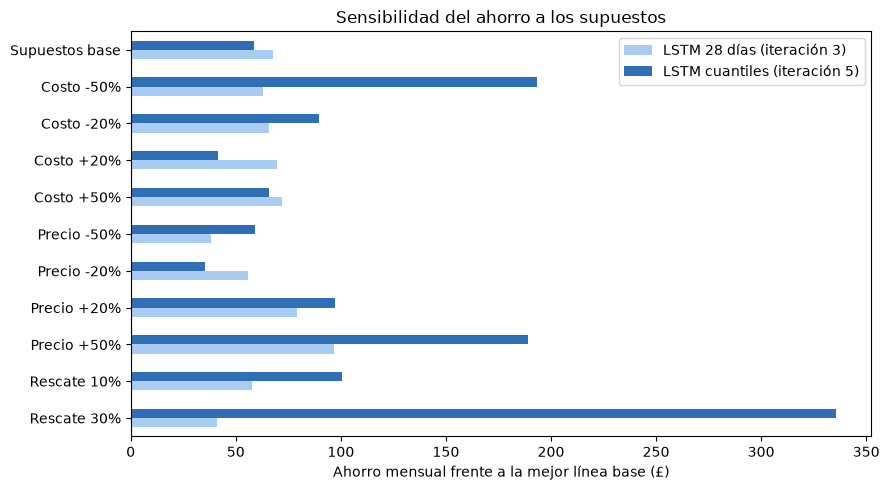

In [26]:
fig, ax = plt.subplots(figsize=(9, 5))
sensitivity.iloc[::-1].plot.barh(ax=ax, color=["#a9ccf2", "#2f6fb5"])
ax.axvline(0, color="gray", linewidth=0.8)
ax.set_xlabel("Ahorro mensual frente a la mejor línea base (£)")
ax.set_title("Sensibilidad del ahorro a los supuestos")
plt.tight_layout()
plt.show()

**Conclusión:** en los 11 escenarios las dos redes ahorran frente a la mejor línea base, así que el resultado no depende de que los supuestos sean exactos. El ahorro de la iteración 3 es estable (entre £38 y £97 al mes), porque produce siempre lo mismo y solo cambia el precio de cada error. El de la iteración 5 varía mucho más (entre £35 y £336), porque al cambiar los costos cambia el q* de cada producto y la red elige otros escalones: cuando producir es barato o lo que sobra se puede recuperar, conviene producir más, y ahí la iteración 5 saca mucha ventaja. Es la ventaja de que la decisión se adapte a los costos de cada negocio.

## **10. Explicabilidad**

Una red neuronal no explica sola sus predicciones, pero hay técnicas para ver en qué se basa. Se aplican dos sobre el modelo de la app (iteración 5, su mediana) en The Bread Basket:

- **Gradientes integrados:** para cada predicción, reparten el resultado entre las entradas. Se compara la entrada real contra una entrada "vacía" (todo en cero) y se mide cuánto cambia la predicción al ir pasando de una a otra; la parte del cambio que corresponde a cada día de la ventana es su atribución. Si la red aprendió el ciclo semanal, los días de hace 7, 14, 21 y 28 días deberían pesar más.
- **Importancia por permutación:** se desordena una sola entrada entre los ejemplos (por ejemplo, los feriados), dejando todo lo demás igual, y se mide cuánto empeora el error. Si empeora mucho, la red depende de esa entrada; si no cambia, la ignora.

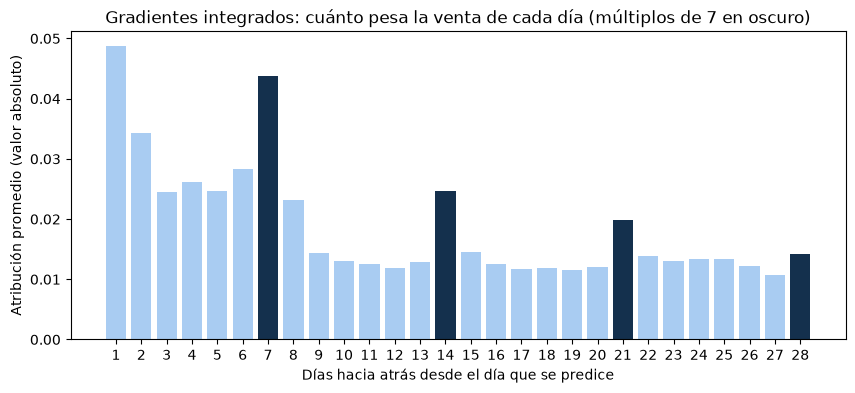

In [27]:
model_q, _, _, _ = models["LSTM cuantiles (iteración 5)"]
bb_w28 = make_subset(make_windows(df, 28, ["test"], first_offset=28), (test_w.meta["dataset"] == "bread_basket").to_numpy())
model_q.eval()


def integrated_gradients(model, past, future, output_day=0, steps=32, batch=512):
    """Atribución de cada día y variable de la ventana a la predicción (mediana) del día indicado."""
    attributions = []
    alphas = torch.linspace(1 / steps, 1, steps, device=DEVICE)
    for i in range(0, len(past), batch):
        x = torch.from_numpy(past[i:i + batch]).to(DEVICE)
        f = torch.from_numpy(future[i:i + batch]).to(DEVICE)
        total = torch.zeros_like(x)
        for alpha in alphas:
            xi = (alpha * x).requires_grad_(True)
            out = model(xi, f)[:, output_day, 0].sum()
            grad, = torch.autograd.grad(out, xi)
            total += grad
        attributions.append((x * total / steps).detach().cpu().numpy())
    return np.concatenate(attributions)


ig = integrated_gradients(model_q, bb_w28.past, bb_w28.future)
lags = np.arange(28, 0, -1)  # la posición 0 de la ventana es el día más lejano (hace 28 días)
sales_attr = pd.Series(np.abs(ig[:, :, 0]).mean(axis=0), index=lags).sort_index()

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(sales_attr.index, sales_attr.values, color=["#14304d" if lag % 7 == 0 else "#a9ccf2" for lag in sales_attr.index])
ax.set_xticks(range(1, 29))
ax.set_xlabel("Días hacia atrás desde el día que se predice")
ax.set_ylabel("Atribución promedio (valor absoluto)")
ax.set_title("Gradientes integrados: cuánto pesa la venta de cada día (múltiplos de 7 en oscuro)")
plt.show()

La atribución de las variables de calendario no se compara con la de las ventas, porque los gradientes integrados la miden contra una entrada "vacía" en la que todos los días están cerrados: casi todos los días reales están abiertos, así que esa comparación exagera el peso de "abierto". Para comparar variables se usa la importancia por permutación, más abajo.

Un ejemplo concreto: la predicción de un sábado de The Bread Basket, con la venta de cada día de la ventana y su atribución. Las barras positivas empujan la predicción hacia arriba y las negativas hacia abajo.

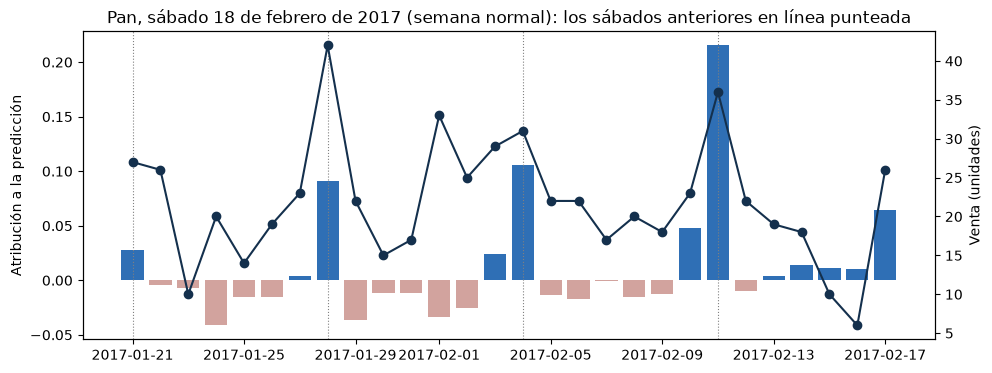

In [28]:
dates = pd.to_datetime(bb_w28.meta["first_date"])


def plot_ig_example(product, date, title):
    """Venta de cada día de la ventana y su atribución a la predicción de ese día."""
    example = int(np.flatnonzero((dates == pd.Timestamp(date)).to_numpy() & (bb_w28.meta["product_id"] == product).to_numpy())[0])
    window_days = pd.date_range(end=dates.iloc[example] - pd.Timedelta(days=1), periods=28)
    weekday = dates.iloc[example].day_of_week
    fig, ax1 = plt.subplots(figsize=(11, 4))
    ax1.bar(window_days, ig[example, :, 0], color=["#2f6fb5" if v >= 0 else "#d2a39e" for v in ig[example, :, 0]])
    ax1.set_ylabel("Atribución a la predicción")
    ax2 = ax1.twinx()
    sales = bb_w28.past[example, :, 0] * bb_w28.scale[example]
    closed = bb_w28.past[example, :, 1] == 0
    ax2.plot(window_days, sales, color="#14304d", marker="o")
    ax2.scatter(window_days[closed], sales[closed], color="#c0392b", zorder=3, label="cerrado")
    ax2.set_ylabel("Venta (unidades)")
    for day in window_days[window_days.day_of_week == weekday]:
        ax1.axvline(day, color="gray", linestyle=":", linewidth=0.8)
    if closed.any():
        ax2.legend(loc="upper left", fontsize=8)
    ax1.set_title(title)
    plt.show()


plot_ig_example("bread_basket_bread", "2017-02-18", "Pan, sábado 18 de febrero de 2017 (semana normal): los sábados anteriores en línea punteada")

Un segundo ejemplo, en una semana atípica: el pan del sábado 7 de enero de 2017. Su ventana incluye la Navidad y el Año Nuevo, con el local cerrado el 25 y 26 de diciembre y el 2 de enero (en rojo), y sábados anteriores fuera de lo normal por las fiestas.

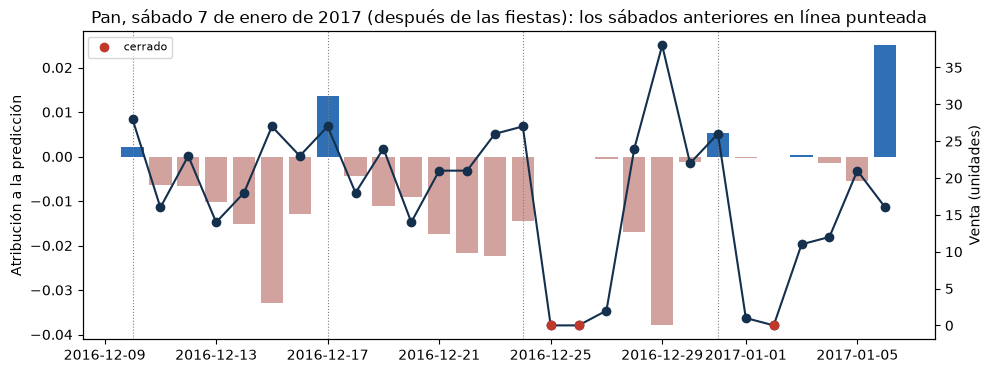

In [29]:
plot_ig_example("bread_basket_bread", "2017-01-07", "Pan, sábado 7 de enero de 2017 (después de las fiestas): los sábados anteriores en línea punteada")

In [30]:
def wape_bb(past, future, w):
    pred = predict_arrays(model_q, past, future)[..., 0] * w.scale[:, None]
    actual = w.target * w.scale[:, None]
    open_ = w.mask == 1
    return np.abs(pred - actual)[open_].sum() / actual[open_].sum()


def predict_arrays(model, past, future, batch=2048):
    outputs = []
    with torch.no_grad():
        for i in range(0, len(past), batch):
            outputs.append(model(torch.from_numpy(past[i:i + batch]).to(DEVICE), torch.from_numpy(future[i:i + batch]).to(DEVICE)).cpu().numpy())
    return np.concatenate(outputs)


rng = np.random.default_rng(123)
groups = {
    "Venta de los últimos 7 días": ("past", [0], slice(21, 28)),
    "Venta de hace 8 a 28 días": ("past", [0], slice(0, 21)),
    "Días abiertos (pasado)": ("past", [1], slice(None)),
    "Feriados (pasado)": ("past", [2, 3], slice(None)),
    "Días abiertos (futuro)": ("future", [0], slice(None)),
    "Feriados (futuro)": ("future", [1, 2], slice(None)),
}
importance = {}
for w_name, w in [("The Bread Basket", bb_w28), ("ddop (5 locales)", make_subset(make_windows(df, 28, ["test"], first_offset=28), (test_w.meta["dataset"] == "ddop").to_numpy()))]:
    base_wape = wape_bb(w.past, w.future, w)
    importance[w_name] = {}
    for name, (part, channels, days) in groups.items():
        past, future = w.past.copy(), w.future.copy()
        target = past if part == "past" else future
        order = rng.permutation(len(target))
        view = target[:, days].copy()
        view[:, :, channels] = view[order][:, :, channels]  # se desordena solo esa entrada entre ejemplos
        target[:, days] = view
        importance[w_name][name] = wape_bb(past, future, w) - base_wape
importance = pd.DataFrame(importance)
importance.round(4).sort_values("The Bread Basket", ascending=False)

,The Bread Basket,ddop (5 locales)
Venta de hace 8 a 28 días,0.0811,0.0836
Venta de los últimos 7 días,0.0675,0.0414
Feriados (futuro),0.0064,0.0069
Días abiertos (pasado),0.0025,0.0032
Feriados (pasado),0.0008,0.0039
Días abiertos (futuro),-0.0004,0.0009


**Conclusiones de la explicabilidad:**

- **La red aprendió el ciclo semanal y la tendencia reciente.** En los gradientes integrados, las ventas que más pesan son las del día anterior y las de hace 7 días, y después las de hace 14, 21 y 28 días; los días intermedios pesan poco. Es el mismo patrón que mostró la autocorrelación en el análisis exploratorio, así que la red llegó sola a lo que muestran los datos.
- **En el ejemplo del pan,** para predecir el sábado 18 de febrero de 2017 las atribuciones más altas están en los sábados anteriores y en el día anterior.
- **La permutación confirma que la red depende de las ventas pasadas y casi nada del calendario:** desordenar las ventas de hace 8 a 28 días sube el WAPE unos 8 puntos, y las de los últimos 7 días entre 4 y 7 puntos; los feriados y los días abiertos lo mueven menos de 1 punto. Los feriados casi no pesan porque en la prueba hay pocos, y los días abiertos porque casi todos lo están.
- **Una advertencia sobre el método:** los gradientes integrados comparan contra una entrada "vacía" con todos los días cerrados, así que exageran el peso de la variable "abierto"; por eso las variables se comparan con la permutación y no con esa atribución.

## **11. Resumen de iteraciones**

Una fila por versión del modelo, con lo que cambió respecto a la anterior, su error en entrenamiento, validación y prueba, el ahorro en dinero y su costo de entrenamiento. El WAPE de entrenamiento se calcula aquí, con los modelos ya entrenados, para ver si alguna versión memorizó en lugar de aprender: un error mucho más bajo en entrenamiento que en validación sería señal de sobreajuste. Todas las columnas de error se miden sobre los mismos días (`first_offset=28`).

In [31]:
import json

changes = {
    "Promedio de los mismos días (28)": (0, "Línea base, sin red neuronal"),
    "MLP (iteración 1)": (1, "Primera red: ve la ventana como una fila de números"),
    "LSTM base (iteración 2)": (2, "Lee los días en orden, ventana de 14 días"),
    "LSTM 28 días (iteración 3)": (3, "Ventana de 28 días en lugar de 14"),
    "LSTM día de la semana (iteración 4)": (4, "Agrega el día de la semana (ventana de 14 días)"),
    "LSTM cuantiles (iteración 5)": (5, "Sobre la iteración 3: predice 9 cuantiles"),
}
histories = {
    "MLP (iteración 1)": MODELS / "01_mlp.json",
    "LSTM base (iteración 2)": MODELS / "search" / f"{search.iloc[0]['nombre']}.json",
    "LSTM 28 días (iteración 3)": MODELS / "03_lstm_28.json",
    "LSTM día de la semana (iteración 4)": MODELS / "04_lstm_dia_semana.json",
    "LSTM cuantiles (iteración 5)": MODELS / "05_lstm_cuantiles.json",
}


def total_wape(windows, prediction):
    pred, actual = prediction * windows.scale[:, None], windows.target * windows.scale[:, None]
    open_ = windows.mask == 1
    return np.abs(pred - actual)[open_].sum() / actual[open_].sum()


train_ref = make_windows(df, 28, ["train"], first_offset=28)
rows = []
for name, (iteration, change) in changes.items():
    if name in models:
        model, _, lookback, dow = models[name]
        w = make_windows(df, lookback, ["train"], use_day_of_week=dow, first_offset=28)
        train_wape = total_wape(w, predict(model, w)[..., 0])
        history = json.loads(histories[name].read_text())
        params, epochs, minutes = sum(p.numel() for p in model.parameters()), len(history), sum(h["seconds"] for h in history) / 60
    else:
        train_wape, params, epochs, minutes = total_wape(train_ref, same_weekday_mean(train_ref)), 0, 0, 0.0
    rows.append({
        "iteración": iteration, "modelo": name, "cambio": change,
        "WAPE entrenamiento": train_wape,
        "WAPE validación": total_wape(val_w, val_preds[name]),
        "WAPE prueba The Bread Basket": bb_results.loc[name, "WAPE"],
        "WAPE prueba ddop": ddop_results.loc[name, "WAPE"],
        "ahorro por mes (£)": daily.loc[name, "ahorro por mes (£)"],
        "parámetros": params, "épocas": epochs, "minutos de entrenamiento": minutes,
    })
summary = pd.DataFrame(rows).set_index("iteración")
summary.round(3)

,modelo,cambio,WAPE entrenamiento,WAPE validación,WAPE prueba The Bread Basket,WAPE prueba ddop,ahorro por mes (£),parámetros,épocas,minutos de entrenamiento
iteración,,,,,,,,,,
0,Promedio de los mismos días (28),"Línea base, sin red neuronal",0.204,0.215,0.423,0.178,0.000,0,0,0.000
1,MLP (iteración 1),Primera red: ve la ventana como una fila de nú...,0.187,0.210,0.404,0.174,51.460,18695,52,0.456
2,LSTM base (iteración 2),"Lee los días en orden, ventana de 14 días",0.186,0.209,0.408,0.176,57.695,17223,63,1.695
3,LSTM 28 días (iteración 3),Ventana de 28 días en lugar de 14,0.182,0.204,0.401,0.170,67.635,17223,43,1.836
4,LSTM día de la semana (iteración 4),Agrega el día de la semana (ventana de 14 días),0.183,0.206,0.410,0.172,57.803,18375,58,2.332
5,LSTM cuantiles (iteración 5),Sobre la iteración 3: predice 9 cuantiles,0.184,0.205,0.413,0.172,58.555,20863,43,3.347


## **12. Costo de inferencia**

En la app el modelo corre una vez al día, como un proceso aparte (servicio batch), para calcular el pronóstico de los 7 días de cada producto. Se mide cuánto tarda en **CPU**, que es donde correrá ese proceso (un servidor gratuito sin GPU), para todos los productos de The Bread Basket a la vez y para las 172 series de los tres datasets. Cada medición se repite 20 veces y se reporta la mediana.

In [32]:
import time

cpu_model = LSTMForecaster(4, 3, quantiles=len(QUANTILES), **lstm_config)
cpu_model.load_state_dict(torch.load(MODELS / "05_lstm_cuantiles.pt", map_location="cpu"))
cpu_model.eval()

latest = make_windows(df, 28, ["train", "val", "test", "test_season"], first_offset=28)
last = latest.meta.groupby(["store_id", "product_id"]).tail(1).index.to_numpy()  # la última ventana de cada serie
cases = {
    "The Bread Basket (20 productos)": last[(latest.meta.loc[last, "dataset"] == "bread_basket").to_numpy()],
    "Las 172 series": last,
}
inference = {}
for name, rows in cases.items():
    past, future = torch.from_numpy(latest.past[rows]), torch.from_numpy(latest.future[rows])
    times = []
    for _ in range(20):
        start = time.perf_counter()
        with torch.no_grad():
            cpu_model(past, future)
        times.append(time.perf_counter() - start)
    seconds = float(np.median(times))
    inference[name] = {"productos": len(rows), "milisegundos en total": seconds * 1000, "milisegundos por producto": seconds * 1000 / len(rows)}
inference = pd.DataFrame(inference).T
inference.round(3)

,productos,milisegundos en total,milisegundos por producto
The Bread Basket (20 productos),20.0,0.877,0.044
Las 172 series,172.0,4.116,0.024


El costo en dinero es cero: el proceso diario corre en GitHub Actions y la app en Vercel, ambos en su plan gratuito. Comparado con la captura del Proyecto 3, que costaba unos US$0.0024 por llamada a Gemini, el pronóstico no tiene costo por predicción.

## **13. Guardar resultados**

Cada tabla de la evaluación se guarda en `results/` con el prefijo `07_`, para el informe y para que quede versionada junto con los resultados de los notebooks anteriores.

In [33]:
outputs = {
    "07_prueba_ddop.csv": ddop_results,
    "07_prueba_bread_basket.csv": bb_results,
    "07_prueba_temporada.csv": season_results,
    "07_calibracion_bread_basket.csv": calibration_bb.set_index("cuantil"),
    "07_regla_redondeo.csv": rule_costs,
    "07_supuestos_valor.csv": assumptions,
    "07_valor_diario.csv": daily,
    "07_error_por_horizonte.csv": horizon,
    "07_curva_valor.csv": curve,
    "07_metrica_vs_valor.csv": tech_vs_value,
    "07_sensibilidad.csv": sensitivity,
    "07_atribucion_por_dia.csv": sales_attr.rename("atribucion_promedio").to_frame().rename_axis("dias_hacia_atras"),
    "07_importancia_permutacion.csv": importance,
    "07_resumen_iteraciones.csv": summary,
    "07_costo_inferencia.csv": inference,
}
for file, table in outputs.items():
    table.to_csv(RESULTS / file)
print("\n".join(sorted(outputs)))

07_atribucion_por_dia.csv
07_calibracion_bread_basket.csv
07_costo_inferencia.csv
07_curva_valor.csv
07_error_por_horizonte.csv
07_importancia_permutacion.csv
07_metrica_vs_valor.csv
07_prueba_bread_basket.csv
07_prueba_ddop.csv
07_prueba_temporada.csv
07_regla_redondeo.csv
07_resumen_iteraciones.csv
07_sensibilidad.csv
07_supuestos_valor.csv
07_valor_diario.csv
